# QUestion 2.c.IV


status: OPTIMAL | objective: 39.97 DKK
daily totals (kWh): import=4.4, export=3.0, pv=21.3, load=22.8
[Saved CSV] -> C:\Documents\DTU\Optimization ENergy system\46750-assignment-1-group-19\results\Q2_quadratic\hourly_base_case.csv


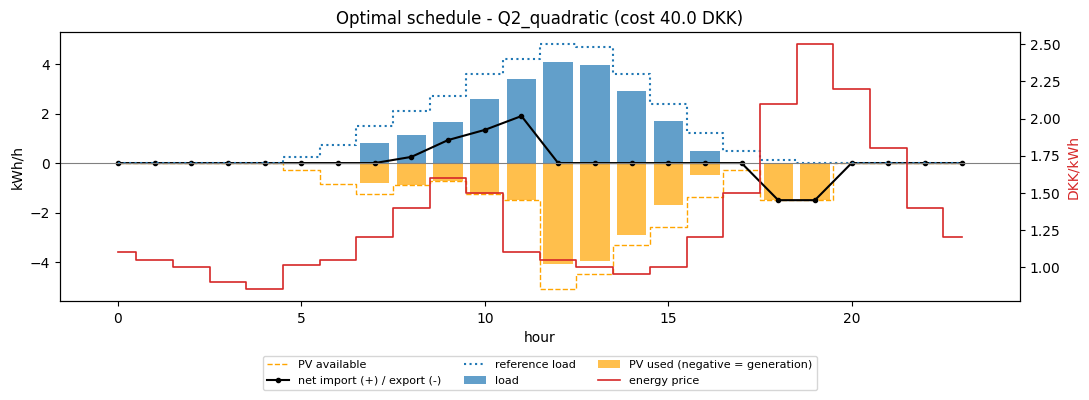

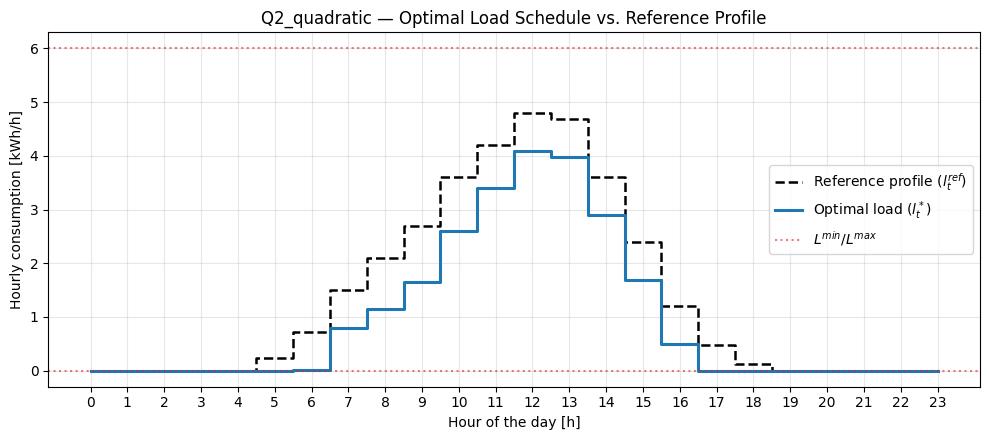

,c^Q [DKK/kWh^2],Procurement Cost [DKK],Total Disutility [DKK],Total Objective [DKK],Daily Energy [kWh],Total Abs. Deviation [kWh],Binding Hours [h]
0,0.01,-1.470,1.105,-0.365,0.000,32.340,24
1,0.05,-1.470,5.524,4.054,0.000,32.340,24
2,0.10,-1.470,11.047,9.577,0.000,32.340,24
3,0.25,8.090,15.433,23.523,6.780,25.560,19
4,0.50,20.851,12.335,33.186,15.540,16.800,15
5,1.00,32.544,7.427,39.971,22.765,9.575,13
6,2.00,39.848,3.955,43.803,27.260,5.080,12
7,5.00,44.476,1.822,46.298,30.110,2.230,11
8,10.00,46.283,0.966,47.250,31.190,1.150,10
9,50.00,47.829,0.193,48.023,32.110,0.230,10


[Saved CSV] -> C:\Documents\DTU\Optimization ENergy system\46750-assignment-1-group-19\results\Q2_quadratic\cQ_sweep_metrics.csv


In [7]:
from pathlib import Path
import matplotlib.pyplot as plt
from src.data_loader import load_question
from src.model import QuadraticConsumerModel
from src.scenarios import run_cQ_sweep
from src.plotting import plot_schedule, plot_load_vs_reference

# 1. Create output directory for Question 2(c)
out_q2c = Path("results/Q2_quadratic")
out_q2c.mkdir(parents=True, exist_ok=True)

# 2. Load data and solve Base Case
data_q2c = load_question("Q2_quadratic")
res_q2c_base = QuadraticConsumerModel(data_q2c).build().solve()
print(res_q2c_base)

# 3. Save Base Case hourly table to CSV
hourly_csv_path = out_q2c / "hourly_base_case.csv"
res_q2c_base.hourly.to_csv(hourly_csv_path, index=False)
print(f"[Saved CSV] -> {hourly_csv_path.resolve()}")

# 4. Plot and save standard schedule figure (save BEFORE plt.show())
fig_sched = plot_schedule(res_q2c_base, data_q2c)
if fig_sched is not None:
    fig_sched.savefig(out_q2c / "schedule_base_case.png", dpi=300, bbox_inches="tight")
else:
    plt.savefig(out_q2c / "schedule_base_case.png", dpi=300, bbox_inches="tight")
plt.show()

# 5. Plot and save Optimal Load vs. Reference Profile
fig_ref = plot_load_vs_reference(
    res_q2c_base, data_q2c, save_path=out_q2c / "load_vs_reference.png"
)
plt.show()

# 6. Run c^Q Parameter Sweep, display, and save to CSV
cQ_grid = [0.01, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0, 10.0, 50.0]
df_sweep_q2c = run_cQ_sweep(data_q2c, cQ_grid)
display(df_sweep_q2c)

sweep_csv_path = out_q2c / "cQ_sweep_metrics.csv"
df_sweep_q2c.to_csv(sweep_csv_path, index=False)
print(f"[Saved CSV] -> {sweep_csv_path.resolve()}")

# Question 3.D

status: OPTIMAL | objective: 63.31 DKK
daily totals (kWh): import=15.5, export=2.4, pv=26.9, load=40.0
duals: {'min_daily_energy': 2.368695651299514}
Dual multiplier mu (min_daily_energy): 2.368695651299514
[Saved CSV] -> C:\Documents\DTU\Optimization ENergy system\46750-assignment-1-group-19\results\Q3\hourly_base_case.csv


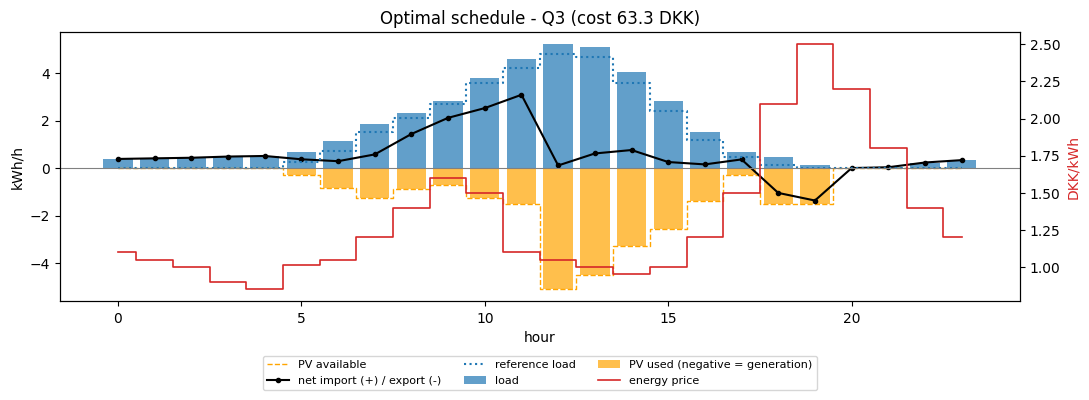

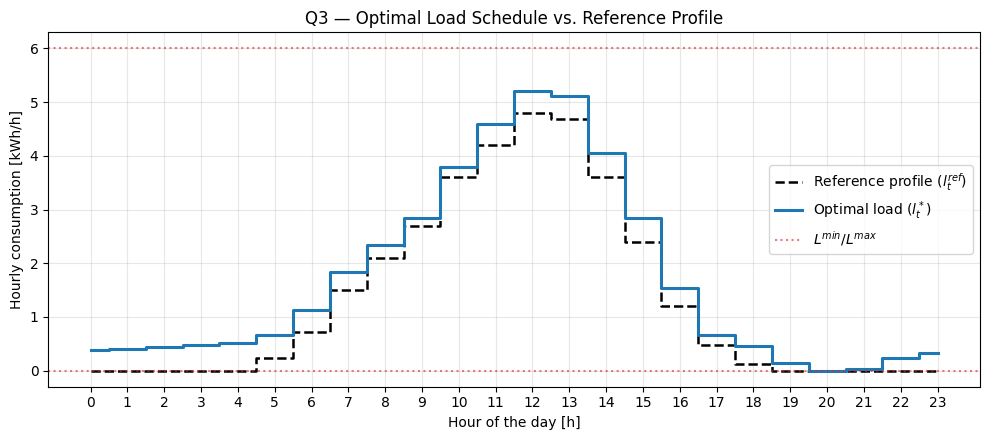

In [13]:
# 1. Create output directory for Question 3
out_q3 = Path("results/Q3")
out_q3.mkdir(parents=True, exist_ok=True)

# 2. Load data and solve Question 3(d)
data_q3 = load_question("Q3")
res_q3 = QuadraticConsumerModel(data_q3).build().solve()
print(res_q3)
print("Dual multiplier mu (min_daily_energy):", res_q3.duals.get("min_daily_energy"))

# 3. Save hourly results to CSV
q3_csv_path = out_q3 / "hourly_base_case.csv"
res_q3.hourly.to_csv(q3_csv_path, index=False)
print(f"[Saved CSV] -> {q3_csv_path.resolve()}")

# 4. Plot and save figures
fig_q3_sched = plot_schedule(res_q3, data_q3)
if fig_q3_sched is not None:
    fig_q3_sched.savefig(out_q3 / "schedule_base_case.png", dpi=300, bbox_inches="tight")
else:
    plt.savefig(out_q3 / "schedule_base_case.png", dpi=300, bbox_inches="tight")
plt.show()

fig_q3_ref = plot_load_vs_reference(
    res_q3, data_q3, save_path=out_q3 / "load_vs_reference.png"
)
plt.show()